# Predicting term-deposit subscriptions (Bank Marketing)

**Problem statement:** We predict whether a client will subscribe to a term deposit (yes/no), for clients contacted in a Portuguese bank's phone marketing campaigns, using the client's personal and banking details and their history with earlier campaigns.

**Data:** `bank-full.csv` from the UCI Machine Learning Repository (Moro, Rita & Cortez, 2014): 45,211 calls, May 2008 – Nov 2010. Download: https://archive.ics.uci.edu/dataset/222/bank+marketing.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, precision_score, recall_score, average_precision_score


seed = 11

## 1. Importing

In [2]:
bank = pd.read_csv("bank-full.csv", sep=";")

print("Rows:", bank.shape[0])
print("Columns:", bank.shape[1])
bank.head()

Rows: 45211
Columns: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
print("Empty cells:", bank.isna().sum().sum())
print("Duplicate rows:", bank.duplicated().sum())

bank.describe()

Empty cells: 0
Duplicate rows: 0


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


## 2. Data cleaning

### Create target variable (y_target)
Convert target variable to binary (1 = subscribed, 0 = did not subscribe)

In [4]:
bank["y_target"] = np.where(bank["y"] == "yes", 1, 0).astype(int)

print("Share of subscribers:", round(bank["y_target"].mean()*100, 4),"%")
print(bank["y_target"].value_counts())

Share of subscribers: 11.6985 %
y_target
0    39922
1     5289
Name: count, dtype: int64


Only about 11% of calls ends in a subscription. For any model the baseline accuracy is 88.3%.

We will evaluate with ROC-AUC, AUPRC, precision and recall, and we **stratify** every split so that each part keeps the same share of subscribers.

### Rebuild the call date

The file has `day` and `month` of the last call, but **no year**. The rows are stored in date order (May 2008 – Nov 2010), so every time the month number goes **down**, a new year has started.

In [5]:
month_number = bank["month"].map({"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
                                  "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12})

bank["year"] = 2008 + (month_number.diff() < 0).cumsum()
bank["date"] = pd.to_datetime(pd.DataFrame({"year": bank["year"],
                                            "month": month_number,
                                            "day": bank["day"]}))

# check: the dates should never go backwards from one row to the next
print("Dates in order:", (bank["date"].diff().dropna() >= pd.Timedelta(0)).all())
print("First call:", bank["date"].min().date())
print("Last call: ", bank["date"].max().date())

bank["year"].value_counts()

Dates in order: True
First call: 2008-05-05
Last call:  2010-11-17


year
2008    27729
2009    14862
2010     2620
Name: count, dtype: int64

The bank moved from mass calling in 2008 (27,729 calls, 5% success) to a small, selected group in 2010 (2,620 calls, 52% success). A random split mixes these years. This is why we add a time-based split.

In [6]:
bank.groupby("year")["y_target"].agg(calls="size", yes_rate="mean")

,calls,yes_rate
year,,
2008,27729,0.050525
2009,14862,0.170637
2010,2620,0.516031


### Handling the "unknown" values

There are no empty cells, but four columns use the category `"unknown"` for missing information. If the success rate differs between "unknown" and known values, the values are **not missing at random**, so we keep "unknown" as its own category instead of dropping rows.

Dropping rows with `poutcome = "unknown"` would delete 82% of the data. We keep "unknown" as a category. Note: `contact = "unknown"` mostly means "called in 2008", so it partly acts as a time stamp.

In [7]:
# contact = "unknown" depends on the year: the channel was simply not recorded in 2008
(bank["contact"] == "unknown").groupby(bank["year"]).mean().round(3)

year
2008    0.460
2009    0.000
2010    0.096
Name: contact, dtype: float64

### Skewed numeric columns

`balance` and `campaign` have long right tails. A few extreme values would stretch the scale that logistic regression is fitted on. We use a log transform: `log(1 + x)` for `campaign`, and a signed log for `balance`.

In [8]:
balance_slog = np.sign(bank["balance"]) * np.log1p(bank["balance"].abs())
campaign_log = np.log1p(bank["campaign"])

## 3. Repeated clients: checking the pseudo-ID

The data has **no client ID**, but the same client can be called in several campaigns. With a random split, one call of a client can end up in the training set and another in the test set. A flexible model (random forest, XGBoost) could then recognise the client instead of learning general patterns, which makes the test score look better than it would be for new clients.

The proposal planned a **pseudo client ID** made of eight profile columns, and group-based CV with it.



### 3.1 The pseudo-ID from the proposal

In [9]:
profile_cols = ["age", "job", "marital", "education", "default", "balance", "housing", "loan"]

bank["row_id"] = bank.index
bank["pseudo_id"] = bank.groupby(profile_cols, sort=False).ngroup()
in_pseudo_group = bank.duplicated(subset=profile_cols, keep=False)

print("Rows that share their profile with another row:", in_pseudo_group.sum(),
      "(" + str(round(100 * in_pseudo_group.mean(), 1)) + "%)")
print("Share of these rows with balance = 0:", round((bank.loc[in_pseudo_group, "balance"] == 0).mean(), 3))
print("Share of all rows with balance = 0:  ", round((bank["balance"] == 0).mean(), 3))

Rows that share their profile with another row: 7255 (16.0%)
Share of these rows with balance = 0: 0.296
Share of all rows with balance = 0:   0.078


**How the pseudo-ID works.** If two rows have exactly the same values in all eight columns, they get the same `pseudo_id`, and we treat them as the same client. Then we mark every row that shares its profile with at least one other row.

**Result.** 7,255 rows (16%) share their exact profile with another row, so the pseudo-ID treats them as repeat clients. But 30% of these rows have a balance of exactly 0 €, against only 8% of all rows. Two different clients are unlikely to share a profile *and* an unusual balance such as 608 €. But 0 € is very common, so many balance-0 groups may be **different clients who only look alike**.

### 3.2 A test with `pdays`

`pdays` is the number of days since the client was last called in an earlier campaign. So if two rows really are the **same client**, the later row should say "contacted before", and its `pdays` should equal the number of days between the two calls. Two different clients who happen to share a profile have no reason to match: `pdays` can take any value from 1 to 871.

We take every pair of consecutive calls within a pseudo-ID group and check this, separately for balance = 0 (a very common value) and other balances.

In [10]:
pairs = bank[in_pseudo_group].sort_values(["pseudo_id", "date"], kind="stable").copy()
pairs["earlier_date"] = pairs.groupby("pseudo_id")["date"].shift()
pairs = pairs.dropna(subset=["earlier_date"])

pairs["days_between_calls"] = (pairs["date"] - pairs["earlier_date"]).dt.days
pairs["later_call_says_contacted_before"] = pairs["pdays"] != -1
pairs["pdays_points_to_earlier_call"] = pairs["pdays"] == pairs["days_between_calls"]
pairs["balance_is_0"] = pairs["balance"] == 0

pairs.groupby("balance_is_0").agg(
    pairs=("pdays", "size"),
    later_call_says_contacted_before=("later_call_says_contacted_before", "mean"),
    pdays_points_to_earlier_call=("pdays_points_to_earlier_call", "mean"),
).round(3)

,pairs,later_call_says_contacted_before,pdays_points_to_earlier_call
balance_is_0,,,
False,2680,0.943,0.915
True,1483,0.210,0.078


**Result.** The pseudo-ID is only partly reliable:

- **Balance ≠ 0:** 94% of the later rows say "contacted before", and in 92% of the pairs the later row's `pdays` points exactly to the date of the earlier call. These are real repeat clients.
- **Balance = 0:** only 21% of the later rows say "contacted before", and only 8% point to the earlier call. Most of these groups are **different clients** who happen to share a common profile (balance 0 is 8% of all rows but 30% of the grouped rows).

It also **misses** repeat clients: it requires the exact same age, so a client who had a birthday between two campaigns gets a different ID. We measure how often this happens below.

### 3.3 A better client ID: link calls through `pdays`

We use the same idea the other way round. For every row with `pdays` ≠ -1, the client's earlier call happened on `date - pdays`. We look for a row on **exactly that date** with the same job, marital status, education, default and balance, and an age that is equal or up to 3 years lower. If exactly one such row exists, we link the two rows as the same client.

In [12]:
link_cols = ["job", "marital", "education", "default", "balance"]

later = bank.loc[bank["pdays"] != -1, ["row_id", "date", "pdays", "age"] + link_cols].copy()
later["earlier_date"] = later["date"] - pd.to_timedelta(later["pdays"], unit="D")

earlier = bank[["row_id", "date", "age"] + link_cols].rename(
    columns={"row_id": "earlier_row_id", "date": "earlier_date", "age": "earlier_age"})

candidates = later.merge(earlier, on=["earlier_date"] + link_cols)
age_gap = candidates["age"] - candidates["earlier_age"]
candidates = candidates[(age_gap >= 0) & (age_gap <= 3)]

# keep only rows with exactly one possible earlier call
n_candidates = candidates.groupby("row_id")["earlier_row_id"].transform("size")
links = candidates[n_candidates == 1].sort_values("row_id")

print("Rows that say 'contacted before':", len(later))
print("- linked to exactly one earlier call:", len(links))
print("- more than one possible earlier call (not linked):", candidates.loc[n_candidates > 1, "row_id"].nunique())
print("- no matching earlier call (not linked):", len(later) - candidates["row_id"].nunique())

Rows that say 'contacted before': 8257
- linked to exactly one earlier call: 6373
- more than one possible earlier call (not linked): 65
- no matching earlier call (not linked): 1819


`poutcome` of the later call is the outcome of the previous campaign. If a link is correct, `poutcome` should be `"success"` when the earlier call ended in a subscription, and `"failure"` when it did not.

In [13]:
check = links.merge(bank[["row_id", "poutcome"]], on="row_id")
check = check.merge(bank[["row_id", "y_target"]].rename(columns={"row_id": "earlier_row_id",
                                                                 "y_target": "earlier_call_subscribed"}),
                    on="earlier_row_id")

pd.crosstab(check["earlier_call_subscribed"], check["poutcome"], normalize="index").round(3)

poutcome,failure,other,success
earlier_call_subscribed,,,
0,0.996,0.004,0.000
1,0.000,0.001,0.999


In [14]:
# same check only for links with balance = 0 (the risky value for the pseudo-ID)
zero = check["balance"] == 0
print("Links with balance = 0:", zero.sum())
pd.crosstab(check.loc[zero, "earlier_call_subscribed"], check.loc[zero, "poutcome"], normalize="index").round(3)

Links with balance = 0: 304


poutcome,failure,other,success
earlier_call_subscribed,,,
0,0.929,0.071,0.000
1,0.000,0.016,0.984


The links agree with `poutcome` in more than 99% of cases. For the 304 links with balance = 0, agreement is a little lower (93% and 98%) but far from chance.

We now give linked rows the same `client_id`.

In [15]:
client_id = bank["row_id"].to_numpy().copy()
for row, earlier_row in zip(links["row_id"], links["earlier_row_id"]):
    client_id[row] = client_id[earlier_row]
bank["client_id"] = client_id

shares_pseudo = bank["pseudo_id"].map(bank["pseudo_id"].value_counts()) > 1
shares_linked = bank["client_id"].map(bank["client_id"].value_counts()) > 1

print("Distinct clients (linked ID):", bank["client_id"].nunique())
print()
print("Rows that share a client with another row")
print("- pseudo-ID (8 profile columns):", shares_pseudo.sum())
print("- linked client ID:             ", shares_linked.sum())
print("- grouped by both:              ", (shares_pseudo & shares_linked).sum())
print()
same_pseudo = (bank.loc[links["row_id"], "pseudo_id"].to_numpy()
               == bank.loc[links["earlier_row_id"], "pseudo_id"].to_numpy())
print("Linked pairs that the pseudo-ID also puts together:", round(same_pseudo.mean(), 3))
print("Linked pairs where the client's age changed:        ", round((links["age"] != links["earlier_age"]).mean(), 3))

Distinct clients (linked ID): 38838

Rows that share a client with another row
- pseudo-ID (8 profile columns): 7255
- linked client ID:              11681
- grouped by both:               5144

Linked pairs that the pseudo-ID also puts together: 0.404
Linked pairs where the client's age changed:         0.595


**Conclusion for the group-based CV.**

- The 8-column pseudo-ID is **not reliable enough**: it groups many different clients with balance 0, and it misses about 60% of the linked repeat calls, because the client's age changed between the two calls in 60% of the linked pairs.
- The `pdays`-linked `client_id` is checked against `poutcome`, a column it never used, and agrees in 99.8% of cases. It finds more repeat calls: 11,681 rows (26%) belong to a client with several calls, against 7,255 with the pseudo-ID.
- **Remaining limitation:** 1,884 of the 8,257 "contacted before" rows (23%) could not be linked (no unique match, e.g. because the balance or profile changed). The group-based CV can therefore still slightly underestimate the effect of repeat clients.

We use `client_id` for the group-based CV.

## 4. Construct final dataset for modelling

### Columns we exclude

- `duration` (call in seconds): It is only known after the call has ended and is strongly associated with the outcome. To avoid **data leakage** duration will be excluded from all predictive models to decide whom to call. 
- `previous`: It repeats the information of `poutcome` and `pday` and has a maximum of 275 contacts which is not realistic.
- `month`: It mostly shows the **year** of the call, not a real seasonal pattern. To test this, we also build a second feature matrix that includes month ???
- `day`: Day of the month of the call: part of the call date, no relevant information about the client.

### Categorial and binary variables

**Reference levels:** Columns 'job', 'marital', 'education', 'contact', 'poutcome' and 'month' are categrorial variables. When creating the dummy variables we use the most common value as reference level: blue-collar (`job`), married (`marital`), secondary (`education`), cellular (`contact`), unknown = never called before (`poutcome`) and may (`month`, only in `X_with_month`). Each coefficient is then read as "compared with the reference level". Random forest and XGBoost do not need this, but it does not hurt them, so all three models use the same features.

In [16]:
# Create final dataframe
bank_clean = bank[["row_id", "client_id", "pseudo_id", "age", "job", "marital", "education", "default", "housing", "loan", "contact", "month", "pdays", "poutcome", "year", "y_target"]]

# numeric
bank_clean["balance_slog"] = balance_slog
bank_clean["campaign_log"] = campaign_log

    
bank_clean["pdays_clean"] = bank["pdays"].where(bank["pdays"] != -1, 0)

# binary columns
for col in ["default", "housing", "loan"]:
    bank_clean[col] = (bank[col] == "yes").astype(int)

# categorical columns: one dummy per value, then drop the reference level (most common value)
categorical = ["job", "marital", "education", "contact", "poutcome", "month"]
reference = ["job_blue-collar", "marital_married", "education_secondary", "contact_cellular", "poutcome_unknown", "month_may"]
dummies = pd.get_dummies(bank[categorical], dtype=int).drop(columns=reference)
bank_clean = bank_clean.join(dummies)
bank_clean = bank_clean.drop(columns=["job", "marital", "education", "contact", "poutcome", "month"])

X = bank_clean.drop(columns=["y_target"])
y = bank["y_target"]

print("Main feature matrix X: ", X.shape)
print(bank_clean.head(6))

Main feature matrix X:  (45211, 44)
   row_id  client_id  pseudo_id  age  default  housing  loan  pdays  year  \
0       0          0          0   58        0        1     0     -1  2008   
1       1          1          1   44        0        1     0     -1  2008   
2       2          2          2   33        0        1     1     -1  2008   
3       3          3          3   47        0        1     0     -1  2008   
4       4          4          4   33        0        0     0     -1  2008   
5       5          5          5   35        0        1     0     -1  2008   

   y_target  ...  month_aug  month_dec  month_feb  month_jan  month_jul  \
0         0  ...          0          0          0          0          0   
1         0  ...          0          0          0          0          0   
2         0  ...          0          0          0          0          0   
3         0  ...          0          0          0          0          0   
4         0  ...          0          0          0

## 5. Splits

We use one main dataset split to select the best model and measure how well it works. We use two additional splits only to check whether the model performs well on different data.

### Main split: stratified random 80/20

The test set is set aside now and used **once, at the very end**, to evaluate the final model.

In [17]:
idx_train, idx_test = train_test_split(bank_clean.index, test_size=0.2, stratify=y, random_state=seed)

X_train, X_test = X.loc[idx_train], X.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

print("Training size:", len(idx_train), "  subscribed rate:", round(y_train.mean(), 3))
print("Test size:    ", len(idx_test), "   subscribed rate:", round(y_test.mean(), 3))

Training size: 36168   subscribed rate: 0.117
Test size:     9043    subscribed rate: 0.117


In [18]:
# How often does a random split put the same client in both sets?
test_client_in_train = bank_clean.loc[idx_test, "client_id"].isin(bank_clean.loc[idx_train, "client_id"])
print("Test rows whose client also has a call in the training set:", test_client_in_train.sum(),
      "(" + str(round(100 * test_client_in_train.mean(), 1)) + "%)")

Test rows whose client also has a call in the training set: 1946 (21.5%)


With a random split, 22% of the test rows belong to a client who also has a call in the training set.

### Time-based splits

In real use, the bank trains on past campaigns and predicts future ones.

- train on **2008**, test on **2009**;
- train on **2008–2009**, test on **2010**.

These splits use all rows, so the test years contain rows of the main test set. We therefore run them **after** the final test evaluation, only as a robustness check, and change nothing in the model afterwards.

Repeat clients are not a problem here: a client called in 2008 and again in 2009 is exactly the situation the bank faces, and their history is in `poutcome` and `pdays`.

In [23]:
time_splits = {
    "train 2008 -> test 2009":      (bank_clean.index[bank_clean["year"] == 2008], bank_clean.index[bank_clean["year"] == 2009]),
    "train 2008-2009 -> test 2010": (bank_clean.index[bank_clean["year"] <= 2009], bank_clean.index[bank_clean["year"] == 2010]),
}

time_table = []
for name, (tr, te) in time_splits.items():
    time_table.append({"split": name,
                       "train rows": len(tr), "test rows": len(te),
                       "train yes rate": y.loc[tr].mean(), "test yes rate": y.loc[te].mean(),
                       "test rows with client seen in training years":
                           bank_clean.loc[te, "client_id"].isin(bank_clean.loc[tr, "client_id"]).mean()})

pd.DataFrame(time_table).round(3)

,split,train rows,test rows,train yes rate,test yes rate,test rows with client seen in training years
0,train 2008 -> test 2009,27729,14862,0.051,0.171,0.219
1,train 2008-2009 -> test 2010,42591,2620,0.092,0.516,0.440


The yes rate in the test years is much higher than in training (17% and 52% vs. 5% and 9%). Predicted probabilities and a threshold chosen on the random split will not transfer directly, so for these splits we mainly compare **ranking** metrics (ROC-AUC, and PR-AUC relative to the test yes rate).

## Variables

| Object | Content |
|---|---|
| `X_train`, `y_train` | Training set (80%), main features |
| `X_test`, `y_test` | Test set (20%): use once, at the end |
| `cv_random` | Stratified 5-fold CV on the training set (main CV) |
| `cv_group`, `groups_train` | Stratified group 5-fold CV with the linked `client_id` |
| `time_splits` | Row indices for the two time-based splits (use `X.loc[...]`, `y.loc[...]`) |
| `bank_clean` | Cleaned data with `year`, `date` and `client_id`, for error analysis by subgroup |

In [20]:
print("X_train:", X_train.shape, "  X_test:", X_test.shape)
print("Features:", X_train.shape[1], "(main),")

X_train: (36168, 44)   X_test: (9043, 44)
Features: 44 (main),


## Cross-validation on the training set: random vs. group-based

All model choices (hyperparameters, model class, threshold) are made with **5-fold cross-validation on the training set**.

- `cv_random`: stratified 5-fold CV, our main CV.
- `cv_group`: stratified **group** 5-fold CV with `client_id`. All calls of a client are in the same fold, so the model is always validated on clients it has not seen.

Running the same model with both and comparing the scores shows how much repeated clients inflate the random-split score. We expect the gap to be small for logistic regression and larger for random forest and XGBoost, which can memorise exact profiles.

split                         lambda
random 80-20                  0.0       0.339124
                              0.1       0.339437
                              1.0       0.338667
                              10.0      0.339794
                              100.0     0.340415
                              1000.0    0.338671
train 2008 -> test 2009       0.0       0.070732
                              0.1       0.070732
                              1.0       0.070732
                              10.0      0.070731
                              100.0     0.070727
                              1000.0    0.071125
train 2008-2009 -> test 2010  0.0       0.233671
                              0.1       0.233388
                              1.0       0.233716
                              10.0      0.234143
                              100.0     0.233675
                              1000.0    0.233667
Name: cv_auprc, dtype: object


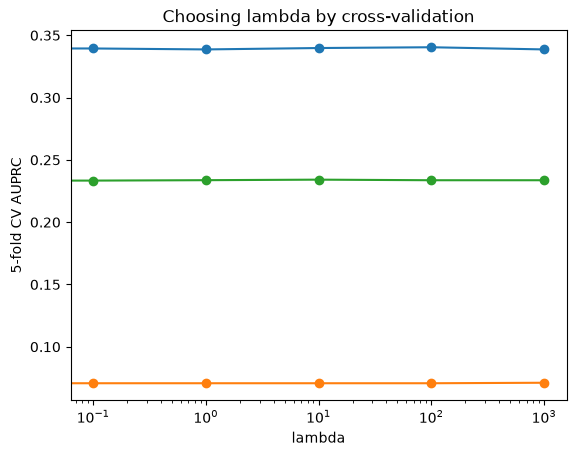

In [30]:
lambdas = [0, 0.1, 1, 10, 100, 1000]
scores = pd.DataFrame(columns=["split", "lambda", "cv_auprc"])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=4)

for lam in lambdas:
    #for testing for lambda = 0, C is set to a very large value to approximate no regularization
    C = 1e10 if lam == 0 else 1/lam
    # lasso logistic regression with penalty strength lam
    model = LogisticRegression(C=C, solver="liblinear", max_iter=5000)

    # 5-fold cross-validated AUPRC of this model on the STANDARDIZED training data
    scores_random = cross_val_score(model, X_train, y_train, cv=cv, scoring="average_precision")
    scores_2 = cross_val_score(model,  
                               X.loc[time_splits["train 2008 -> test 2009"][0]],
                               y.loc[time_splits["train 2008 -> test 2009"][0]],
                               cv=cv, scoring="average_precision")
    scores_3 = cross_val_score(model,
                               X.loc[time_splits["train 2008-2009 -> test 2010"][0]],
                               y.loc[time_splits["train 2008-2009 -> test 2010"][0]],
                               cv=cv, scoring="average_precision")

    # store the average AUPRC over the 5 folds
    scores = pd.concat([scores, pd.DataFrame({"split": "random 80-20", "lambda": lam, "cv_auprc": scores_random})])
    scores = pd.concat([scores, pd.DataFrame({"split": "train 2008 -> test 2009", "lambda": lam, "cv_auprc": scores_2})])
    scores = pd.concat([scores, pd.DataFrame({"split": "train 2008-2009 -> test 2010", "lambda": lam, "cv_auprc": scores_3})])
    #print("lambda =", lam, "  CV AUPRC =", round(scores["cv_auprc"].mean(), 4))


cv_auprc = scores.groupby(["split", "lambda"])["cv_auprc"].mean()
print(cv_auprc)
for split in cv_auprc.index.get_level_values(0).unique():
    plt.plot(lambdas, cv_auprc.loc[split], marker="o", label=split)
plt.xscale("log")
plt.xlabel("lambda")
plt.ylabel("5-fold CV AUPRC")
plt.title("Choosing lambda by cross-validation")
plt.show()

Both schemes keep the yes rate equal across folds. With `cv_group`, no validation row has its client in the training folds.

### Logistic regression

Missed subscribers are usually the most expensive mistake, so the model should favour recall (finding as many subscribers as possible) while keeping precision high enough to avoid wasted calls. Rather than using a default 0.5 cut-off, the decision threshold will be chosen to reflect this cost difference. 

For logistic regression **random split with lambda = 100 is chosen**

### Random Forest

### XGBoost

## Validation: stratified 5-fold cross-validation

We will evaluate the model using stratified 5-fold cross-validation and compare precision and recall across different thresholds. As we do not have reliable monetary cost estimates, we will assess the trade-off between these metrics.